# 07 · Effect on the training pool

**Question:** if the reclassified segments replaced the current v7 segments as model training data, how would the training pool
change: its height distribution by land cover, the share of short vegetation, and the share of segments whose height changes
by more than 2 m?

This uses the matched segments from notebook 04 (G-LiHT tiles) and notebook 01 (Seward). The step through the height-to-biomass
models and `mapBoreal` (plan §4.6) runs in the R pipeline and is not done here: the new segments carry the same RH columns
(canopy-only, ATL08 style) plus GEDI-style RH over ground + canopy photons (`rh*_gedi`), which match the definitions the GEDI
biomass models expect.

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes (v0.1)** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds in `config/atl03_reclass_v0.1.yaml`. |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments (ATL08-style along-track segments), three versions from the same photons**
| Term | Photon classes used | 30 m binning | Role |
|---|---|---|---|
| **current v7 30 m (ATL08 classes → PhoREAL)** | ATL08 v007 | SlideRule PhoREAL (as in `process_atl08_boreal.py`) | What our training files contain today |
| **ATL08 classes → our 30 m (check)** | ATL08 v007 | ours (`segment_metrics`) | Check: separates the effect of our binning from our classification |
| **reclassified photons → our 30 m (new)** | reclassified v0.1 | ours (`segment_metrics`) | The new product being tested |

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.1.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)
FIG = WORK / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.1 d49984a76293 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "7d697cc",
 "git_dirty_lib_or_config": true,
 "config_version": "0.1",
 "config_sha1": "d49984a76293",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-15T09:23:31"
}


## Load the matched segments

**Input:** the three versions of 30 m segments for the G-LiHT tiles (notebook 04) and the Seward transects (notebook 01);
only segments that have a **current v7 30 m** match. Land cover from the ATL08 `segment_landcover` (ESA WorldCover codes).
`change` = new − current `h_canopy`.

In [2]:
segs = pd.concat([gpd.read_parquet(f) for f in sorted((WORK / "segments").glob("tile_*_segments.parquet"))], ignore_index=True)
sew = pd.concat([gpd.read_parquet(f) for f in sorted((WORK / "seward").glob("*_segments.parquet"))], ignore_index=True).assign(region="Seward")
s = pd.concat([segs, sew], ignore_index=True)
s = s[s.h_canopy_phoreal.notna()]
WC = {10: "tree", 20: "shrub", 30: "grass", 40: "crop", 50: "built", 60: "bare/sparse", 70: "snow/ice", 80: "water",
      90: "wetland", 95: "mangrove", 100: "moss/lichen"}
s["landcover"] = s.get("segment_landcover", pd.Series(np.nan, index=s.index)).map(WC).fillna("unknown")
s["change"] = s.h_canopy - s.h_canopy_phoreal
print(len(s), "matched segments")

34508 matched segments


In [3]:
summ = s.groupby(["region", "landcover"]).agg(n=("change", "size"),
                                             current_median=("h_canopy_phoreal", "median"), new_median=("h_canopy", "median"),
                                             current_p95=("h_canopy_phoreal", lambda v: v.quantile(0.95)), new_p95=("h_canopy", lambda v: v.quantile(0.95)),
                                             short_veg_flag=("short_veg_flag", "mean"),
                                             changed_gt_2m=("change", lambda v: (v.abs() > 2).mean())).round(2)
summ[summ.n >= 30]

n  current_median  new_median  current_p95  new_p95  \
region   landcover                                                              
Interior bare/sparse    178            5.52        5.09    15.290000    13.19   
         grass         3255            0.92        0.00     7.870000     5.52   
         shrub         2690            0.86        0.00     5.350000     2.52   
         unknown      14686            3.65        0.00    15.810000    13.69   
         water          288            0.18        0.00     6.900000     1.25   
Kenai    bare/sparse     71            4.81        4.77    16.160000    25.92   
         built          125            4.49        0.00    17.110001     7.46   
         grass          626            5.01        2.78    20.459999    15.42   
         shrub          138            2.52        1.57    21.000000    13.95   
         snow/ice       253            2.82        3.66    25.660000    11.90   
         unknown       9342            4.08        0.00    19.639999    17.13   
         water          179            0.20        0.00     4.260000     0.00   
         wetland        734            0.38        0.00     8.080000     3.53   
Seward   grass          477            1.32        0.00     5.640000     3.75   
         shrub          295            2.63        1.93     5.160000     4.35   
         unknown       1164            3.34        0.00     9.230000     4.07   

                      short_veg_flag  changed_gt_2m  
region   landcover                                   
Interior bare/sparse            0.13           0.53  
         grass                  0.70           0.20  
         shrub                  0.74           0.17  
         unknown                0.62           0.48  
         water                  0.94           0.06  
Kenai    bare/sparse            0.14           0.58  
         built                  0.72           0.46  
         grass                  0.43           0.43  
         shrub                  0.35           0.30  
         snow/ice               0.11           0.43  
         unknown                0.58           0.46  
         water                  0.98           0.08  
         wetland                0.88           0.13  
Seward   grass                  0.64           0.14  
         shrub                  0.28           0.17  
         unknown                0.59           0.52

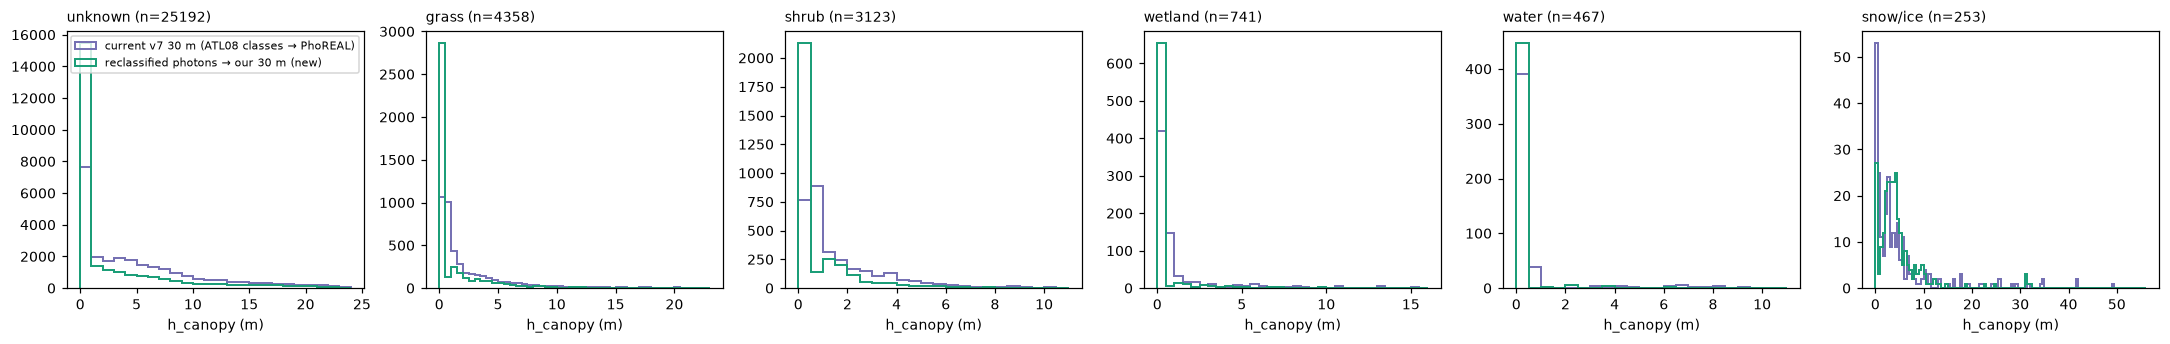

In [4]:
lcs = [lc for lc, n in s.landcover.value_counts().items() if n >= 100][:6]
fig, axes = plt.subplots(1, len(lcs), figsize=(3.3 * len(lcs), 3.2), squeeze=False)
for ax, lc in zip(axes[0], lcs):
    g = s[s.landcover == lc]
    bins = np.arange(0, max(5, np.nanpercentile(g.h_canopy_phoreal, 99)) + 1, 0.5 if g.h_canopy_phoreal.median() < 3 else 1)
    ax.hist(g.h_canopy_phoreal, bins=bins, histtype="step", lw=1.3, color=val.SCHEME_COLORS[val.LABEL_CURRENT], label=val.LABEL_CURRENT)
    ax.hist(g.h_canopy, bins=bins, histtype="step", lw=1.3, color=val.SCHEME_COLORS[val.LABEL_NEW], label=val.LABEL_NEW)
    ax.set_title(f"{lc} (n={len(g)})", loc="left", fontsize=9); ax.set_xlabel("h_canopy (m)")
axes[0, 0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "07_training_pool_by_landcover.png", dpi=150)

## Results
Summarise after review. The decision to scale out (notebook 08) rests on notebooks 05 and 06; this notebook shows how much the
training pool would move.